# UTS Computer Vision Advance
**Nama:** Muhammad Al Farisy | **NIM:** 251012000019 | **Kelas:** UNPAM MTI REG C (Sabtu)

**Topik:** Object Detection menggunakan Faster R-CNN (MobileNetV3-Large 320 FPN) pada dataset Roboflow format COCO.

Alur: Install -> Import -> Download dataset -> Dataset & DataLoader -> Model -> Evaluasi mAP -> Training -> Kurva loss -> Evaluasi model terbaik -> Visualisasi prediksi -> Simpan ke Google Drive.

> Pastikan runtime memakai GPU: *Runtime > Change runtime type > T4 GPU*.

# 1. Instalasi Library Pendukung
Pada tahap pertama ini, kita melakukan instalasi dua pustaka utama yang dibutuhkan:
* **Roboflow**: Pustaka resmi dari platform Roboflow yang digunakan untuk mengunduh dataset secara terstruktur menggunakan API key.
* **Pycocotools**: Pustaka standar untuk memproses anotasi berformat COCO (Common Objects in Context) dan melakukan evaluasi metrik deteksi objek seperti mAP (mean Average Precision).

In [1]:
!pip install roboflow pycocotools -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 85.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.9 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Import Library dan Konfigurasi Hyperparameter
Di sini kita mengimpor modul penting untuk deep learning dan pengolahan gambar:
* **PyTorch & Torchvision**: Framework utama untuk membangun model, memuat arsitektur Faster R-CNN, serta melakukan manipulasi tensor gambar.
* **Matplotlib**: Digunakan untuk menampilkan visualisasi gambar dan menggambar bounding box hasil deteksi.
* **Hyperparameter**: Kita menentukan parameter penting seperti ukuran batch (`BATCH_SIZE = 4`), jumlah epoch training (`NUM_EPOCHS = 3`), learning rate (`0.005`), serta memprioritaskan penggunaan GPU (CUDA) agar proses komputasi jauh lebih cepat.

In [3]:
import os
import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as F
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from PIL import Image
from roboflow import Roboflow

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Device: {device}")
if device.type == "cpu":
    print("[WARNING] GPU tidak aktif! Runtime > Change runtime type > T4 GPU")

NUM_TRAIN_IMAGES = 300
NUM_VALID_IMAGES = 100
BATCH_SIZE = 4
NUM_EPOCHS = 3
LEARNING_RATE = 0.005
FREEZE_BACKBONE = False
MODEL_PATH = "rcnn_best_model.pth"

[INFO] Device: cuda


# 3. Mengunduh Dataset dari Roboflow
Langkah ini berfungsi untuk mendownload dataset deteksi objek langsung dari workspace Roboflow menggunakan format COCO.
* Kode ini mengamankan API key menggunakan fitur **Colab Secrets** (`ROBOFLOW_API_KEY`) untuk menjaga privasi kredensial.
* Dataset yang diunduh otomatis dipisahkan menjadi folder `train`, `valid`, dan `test` lengkap dengan gambar dan file anotasi JSON (`_annotations.coco.json`).

In [5]:
try:
    from google.colab import userdata
    api_key = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    api_key = None

if not api_key:
    api_key = os.getenv("ROBOFLOW_API_KEY", "SrfsDfr3mMFtS1yvmHbK")

assert api_key, "API key belum diatur."

rf = Roboflow(api_key=api_key)
project = rf.workspace("binus-ad9ph").project("rcnn-s7kpd")
dataset = project.version(1).download("coco")

lokasi_dataset = dataset.location
print(f"[INFO] Dataset tersimpan di: {lokasi_dataset}")
print("[INFO] Isi folder:", os.listdir(lokasi_dataset))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to RCNN-1 in coco:: 100%|██████████| 632/632 [00:00<00:00, 6943.18it/s]

[INFO] Dataset tersimpan di: /content/RCNN-1
[INFO] Isi folder: ['test', 'README.dataset.txt', 'README.roboflow.txt', 'valid', 'train']


# 4. Kustomisasi Dataset dan DataLoader
Deteksi objek memerlukan struktur target yang spesifik (bukan hanya gambar dan satu label):
* **CustomCOCODataset**: Kelas kustom berbasis PyTorch Dataset untuk membaca file gambar dan memparsing anotasi bounding box (`[x, y, w, h]`) serta kategori objek dari file JSON COCO.
* **DataLoader**: Digunakan untuk mengelompokkan data ke dalam beberapa batch (`BATCH_SIZE`) secara otomatis, melakukan pengacakan data (*shuffle*) saat latihan, serta mengoptimalkan pemuatan data menggunakan multi-processing (`num_workers=2`).

In [6]:
class CustomCOCODataset(Dataset):
    def __init__(self, root_dir, annotation_file):
        self.root_dir = root_dir
        self.coco = COCO(annotation_file)
        self.ids = sorted(self.coco.imgs.keys())

    def __getitem__(self, index):
        img_id = self.ids[index]
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))
        file_name = self.coco.loadImgs(img_id)[0]["file_name"]
        img = Image.open(os.path.join(self.root_dir, file_name)).convert("RGB")

        boxes, labels = [], []
        for ann in anns:
            x, y, w, h = ann["bbox"]
            if w > 1 and h > 1:
                boxes.append([x, y, x + w, y + h])
                labels.append(ann["category_id"])

        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels, "image_id": torch.tensor([img_id])}
        return F.to_tensor(img), target

    def __len__(self):
        return len(self.ids)

def collate_fn(batch):
    return tuple(zip(*batch))

train_dir = os.path.join(lokasi_dataset, "train")
valid_dir = os.path.join(lokasi_dataset, "valid")
train_ann = os.path.join(train_dir, "_annotations.coco.json")
valid_ann = os.path.join(valid_dir, "_annotations.coco.json")

train_dataset = CustomCOCODataset(train_dir, train_ann)
valid_dataset = CustomCOCODataset(valid_dir, valid_ann)

train_small = Subset(train_dataset, range(min(NUM_TRAIN_IMAGES, len(train_dataset))))
valid_small = Subset(valid_dataset, range(min(NUM_VALID_IMAGES, len(valid_dataset))))

valid_img_ids = [valid_dataset.ids[i] for i in valid_small.indices]

train_loader = DataLoader(train_small, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, num_workers=2)
valid_loader = DataLoader(valid_small, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=collate_fn, num_workers=2)

print(f"[INFO] Train: {len(train_small)} gambar | Valid: {len(valid_small)} gambar")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
[INFO] Train: 300 gambar | Valid: 100 gambar


# 5. Membangun Arsitektur Model Faster R-CNN
Kita menggunakan model **Faster R-CNN** dengan tulang punggung (**backbone**) **MobileNetV3-Large 320 FPN** yang sangat ringan, efisien, dan cocok untuk perangkat dengan spesifikasi terbatas (seperti mobile atau komputasi cepat di cloud):
* `build_model`: Berfungsi mengunduh arsitektur pra-latih (*pretrained weights*) lalu menyesuaikan lapisan akhir penilai kelas (**box predictor**) agar cocok dengan jumlah kelas yang ada di dataset kita (6 kelas termasuk latar belakang/background).
* **Optimizer**: Menggunakan Stochastic Gradient Descent (SGD) dengan momentum dan weight decay untuk meminimalkan loss fungsi secara stabil.
* **LR Scheduler**: Berfungsi menurunkan learning rate secara berkala setiap 2 epoch agar model dapat mengonvergensi bobotnya dengan lebih halus menjelang akhir pelatihan.

In [7]:
coco_train = train_dataset.coco
cat_ids = coco_train.getCatIds()
class_names = {c["id"]: c["name"] for c in coco_train.loadCats(cat_ids)}
print("[INFO] Kategori:", class_names)

num_classes = max(cat_ids) + 1
print(f"[INFO] num_classes (termasuk background): {num_classes}")


def build_model(num_classes, pretrained=True):
    weights = "DEFAULT" if pretrained else None
    m = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn(weights=weights)
    in_features = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return m


model = build_model(num_classes).to(device)

if FREEZE_BACKBONE:
    for p in model.backbone.parameters():
        p.requires_grad = False

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LEARNING_RATE, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)

[INFO] Kategori: {0: 'cars', 1: 'Ambulance', 2: 'Bus', 3: 'Car', 4: 'Motorcycle', 5: 'Truck'}
[INFO] num_classes (termasuk background): 6
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 194MB/s]


# 6. Fungsi Evaluasi Menggunakan COCO mAP
Untuk mengukur kinerja model deteksi objek secara akurat, kita tidak bisa menggunakan akurasi biasa. Kita menggunakan standar COCO Evaluation:
* Fungsi `evaluate_map` memprediksi seluruh gambar pada set validasi/tes.
* Hasil koordinat prediksi diubah ke format COCO (`[x, y, width, height]`) dan dibandingkan dengan data kebenaran (*Ground Truth*).
* Outputnya adalah nilai **mAP@[0.5:0.95]** (metrik ketat dengan IoU berkisar dari 50% hingga 95%) dan **mAP@0.5** (mAP longgar dengan IoU minimal 50%).

In [8]:
def evaluate_map(model, data_loader, coco_gt, device, img_ids, verbose=True):
    """Mengembalikan (mAP@[0.5:0.95], mAP@0.5)."""
    model.eval()
    results = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            outputs = model(images)

            for target, output in zip(targets, outputs):
                image_id = target["image_id"].item()
                for box, score, label in zip(output["boxes"].cpu().numpy(),
                                             output["scores"].cpu().numpy(),
                                             output["labels"].cpu().numpy()):
                    xmin, ymin, xmax, ymax = box
                    results.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": [float(xmin), float(ymin),
                                 float(xmax - xmin), float(ymax - ymin)],
                        "score": float(score),
                    })

    if not results:
        print("  [EVAL WARNING] Tidak ada prediksi pada data validasi.")
        return 0.0, 0.0

    coco_dt = coco_gt.loadRes(results)
    coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
    coco_eval.params.imgIds = img_ids
    coco_eval.evaluate()
    coco_eval.accumulate()
    if verbose:
        coco_eval.summarize()
    return coco_eval.stats[0], coco_eval.stats[1]

# 7. Proses Pelatihan (Training Loop)
Ini adalah inti dari pembuatan AI model di mana bobot jaringan saraf diperbarui:
* Setiap batch gambar dan target dikirimkan ke GPU.
* Model menghitung 4 jenis akumulasi loss sekaligus: loss klasifikasi kelas objek, loss regresi posisi bounding box, loss keaktifan objek (*objectness*), dan loss kecocokan wilayah usulan (RPN box reg).
* Setelah tiap epoch berakhir, model divalidasi dengan fungsi `evaluate_map`. Jika performa mAP validasi meningkat dibanding epoch sebelumnya, model dengan parameter terbaik saat itu juga langsung disimpan secara otomatis ke dalam file `rcnn_best_model.pth`.

In [9]:
coco_valid_gt = valid_dataset.coco
best_map = float("-inf")
history = {"train_loss": [], "map": [], "map50": []}

print(f"Total batch per epoch: {len(train_loader)}")

for epoch in range(NUM_EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")
    model.train()
    epoch_loss = 0.0

    for batch_idx, (images, targets) in enumerate(train_loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(train_loader):
            print(f"  Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {losses.item():.4f}")

    lr_scheduler.step()
    avg_loss = epoch_loss / len(train_loader)
    print(f"[Epoch {epoch+1}] Avg Loss: {avg_loss:.4f}")

    print("--- Evaluasi Validation ---")
    current_map, current_map50 = evaluate_map(model, valid_loader, coco_valid_gt, device, valid_img_ids)

    history["train_loss"].append(avg_loss)
    history["map"].append(current_map)
    history["map50"].append(current_map50)

    if current_map > best_map:
        best_map = current_map
        torch.save(model.state_dict(), MODEL_PATH)
        print(f"  Model terbaik disimpan ke {MODEL_PATH} (mAP={best_map:.4f})")

print("\n=========== TRAINING SELESAI ===========")
print(f"Best mAP@[0.5:0.95] = {best_map:.4f}")

Total batch per epoch: 75

--- Epoch 1/3 ---
  Batch [10/75] | Loss: 2.3687
  Batch [20/75] | Loss: 1.3093
  Batch [30/75] | Loss: 1.4946
  Batch [40/75] | Loss: 0.6718
  Batch [50/75] | Loss: 0.8342
  Batch [60/75] | Loss: 0.9117
  Batch [70/75] | Loss: 1.6005
  Batch [75/75] | Loss: 1.2577
[Epoch 1] Avg Loss: 1.2552
--- Evaluasi Validation ---
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.13s).
Accumulating evaluation results...
DONE (t=0.05s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.274
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.488
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.259
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.019
 Average Precision  (AP) @[ IoU=0.50:0.9

### **Analisis Hasil Log Pelatihan (Training Loop)**

Jika kita perhatikan log keluaran proses training selama 3 epoch di atas, ada beberapa poin penting yang menarik untuk dibahas mengenai performa model Faster R-CNN kita:

#### **1. Mekanisme Batch dan Epoch**
* **`Total batch per epoch: 75`**: Berhubung kita memakai total 300 gambar latihan dengan `BATCH_SIZE = 4`, data otomatis dibagi menjadi 75 batch per epoch. Artinya, model melakukan pembaruan bobot (*backpropagation*) sebanyak 75 kali di setiap epochnya.

#### **2. Tren Penurunan Loss**
Loss di sini merupakan tolok ukur seberapa jauh tebakan model meleset dari target asli (*ground truth*).
* **Epoch 1**: Proses dimulai dengan loss yang cukup tinggi di angka **2.36** pada batch awal, kemudian berhasil ditekan hingga rata-rata (**Avg Loss**) menyentuh **1.2552** di akhir epoch.
* **Epoch 2**: Rata-rata loss terus menyusut ke angka **0.9488**.
* **Epoch 3**: Model menutup fase latihan dengan hasil terbaiknya di rata-rata loss **0.7362**.
* **Kesimpulan**: Tren penurunan loss yang konsisten dari **1.25** ke **0.73** ini menunjukkan proses belajar model berjalan dengan sehat (*converging*) dan tidak mengalami kendala stagnasi.

#### **3. Evaluasi Metrik COCO (mAP & Recall)**
Evaluasi berkala dilakukan setiap kali satu epoch selesai menggunakan data validasi:

* **Average Precision (AP) / mAP**:
  * **`AP @[ IoU=0.50:0.95 ]`**: Ini adalah metrik standar COCO yang paling ketat. Skor model melesat dari **27.4%** (Epoch 1) naik menjadi **36.7%** (Epoch 2), dan puncaknya di **41.6%** (Epoch 3). Tren positif ini menunjukkan akurasi penempatan kotak pembatas (*bounding box*) makin presisi seiring bertambahnya epoch.
  * **`AP @[ IoU=0.50 ]` (mAP@50)**: Pada toleransi posisi kotak pembatas yang lebih longgar (minimal tumpang tindih 50%), akurasi model meningkat dari **48.8%** hingga menyentuh **62.2%** di akhir training. Ini menandakan model sudah sangat andal mengenali keberadaan objek secara umum.

* **Analisis Berdasarkan Ukuran Objek (`area`)**:
  * **`small` (0.000)**: Model belum mampu mendeteksi objek yang sangat kecil. Hal ini wajar dan dapat dimaklumi karena arsitektur MobileNetV3-Large yang diringkas (dimensi resolusi input 320px) secara inheren membatasi retensi fitur mikro demi mengejar kecepatan.
  * **`medium` (2.0%) & `large` (46.1%)**: Model bekerja jauh lebih optimal pada objek berukuran sedang dan sangat tajam saat mendeteksi objek besar (seperti mobil/truk di baris depan).

* **Average Recall (AR)**:
  * Nilai **`AR @[ IoU=0.50:0.95 ]`** berada di angka **56.9%** pada Epoch 3, yang berarti model berhasil menemukan sekitar 56.9% dari total keseluruhan objek yang seharusnya terdeteksi pada gambar.

#### **4. Mekanisme Penyimpanan Otomatis (Auto-Save)**
* Setiap kali epoch berakhir, sistem akan membandingkan mAP saat ini dengan mAP terbaik sebelumnya. Karena performa terus menanjak secara konsisten (**0.2743** $
ightarrow$ **0.3670** $
ightarrow$ **0.4163**), bobot model terbaik selalu diperbarui dan aman disimpan dalam berkas `rcnn_best_model.pth`.

# 8. Analisis Kurva Pelatihan
Visualisasi grafis sangat penting untuk menganalisis performa training:
* **Kurva Kiri (Training Loss)**: Menunjukkan penurunan nilai loss dari epoch ke epoch. Semakin menurun dan melandai, mengindikasikan model belajar mengenali pola gambar dengan baik.
* **Kurva Kanan (Validation mAP)**: Menampilkan peningkatan akurasi lokalisasi objek. Di sini kita dapat memantau apakah model mengalami *underfitting* (nilai mAP terlalu rendah) atau *overfitting* (jika grafik loss turun tajam tapi mAP validasi justru menurun).

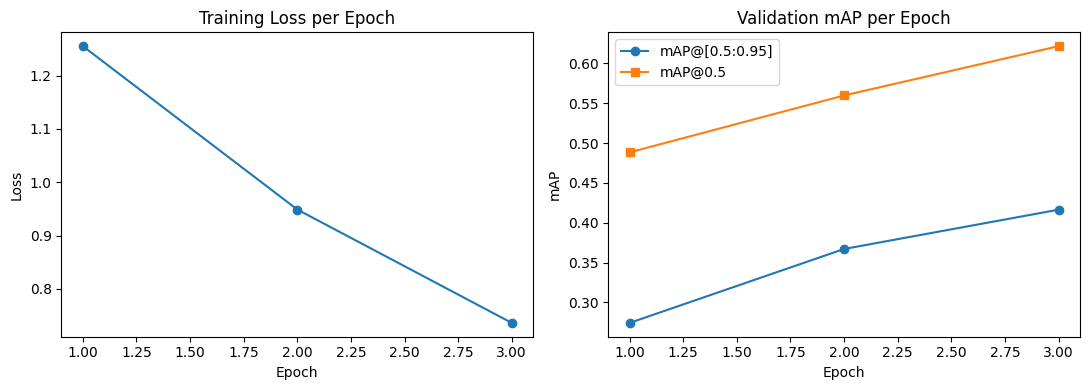

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(epochs, history["train_loss"], marker="o")
ax[0].set_title("Training Loss per Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")

ax[1].plot(epochs, history["map"], marker="o", label="mAP@[0.5:0.95]")
ax[1].plot(epochs, history["map50"], marker="s", label="mAP@0.5")
ax[1].set_title("Validation mAP per Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("mAP")
ax[1].legend()

plt.tight_layout()
plt.show()

# 9. Evaluasi Akhir Model Terbaik pada Data Validasi & Tes
Setelah seluruh proses latihan selesai, kita menguji keandalan model terbaik yang disimpan:
* Bobot terbaik dari file `rcnn_best_model.pth` dimuat ulang ke dalam arsitektur model kosong.
* Model tersebut dievaluasi menggunakan data validasi serta data tes independen (`test_dataset`) yang sama sekali belum pernah dilihat oleh model selama masa pelatihan untuk memastikan kemampuan generalisasi model di dunia nyata.

In [11]:
best_model = build_model(num_classes, pretrained=False)
best_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
best_model.to(device)

print("=== Validation (model terbaik) ===")
map_val, map50_val = evaluate_map(best_model, valid_loader, coco_valid_gt, device, valid_img_ids)
print(f"mAP@[0.5:0.95] = {map_val:.4f} | mAP@0.5 = {map50_val:.4f}")

test_dir = os.path.join(lokasi_dataset, "test")
test_ann = os.path.join(test_dir, "_annotations.coco.json")
if os.path.exists(test_ann):
    test_dataset = CustomCOCODataset(test_dir, test_ann)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                             collate_fn=collate_fn, num_workers=2)
    print("\n=== Test (model terbaik) ===")
    map_test, map50_test = evaluate_map(best_model, test_loader, test_dataset.coco,
                                        device, test_dataset.ids)
    print(f"mAP@[0.5:0.95] = {map_test:.4f} | mAP@0.5 = {map50_test:.4f}")
else:
    print("\n[INFO] Folder test tidak ditemukan, evaluasi test dilewati.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 164MB/s]


=== Validation (model terbaik) ===
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.08s).
Accumulating evaluation results...
DONE (t=0.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.416
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.622
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.448
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.020
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.461
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.435
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.569
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.569
 Average Recall     (AR) @[ IoU=0

### **Analisis Hasil Evaluasi Akhir Model Terbaik (Validation & Test)**

Di bagian ini, kita menguji keandalan asli model terbaik kita (`rcnn_best_model.pth`) menggunakan data validasi serta data uji (*test set*) yang sepenuhnya belum pernah dilihat model selama masa pelatihan. Ini adalah simulasi krusial untuk mengukur performa sistem di kondisi nyata.

---

#### **1. Pengunduhan Bobot Dasar Backbone (MobileNetV3)**
* **`Downloading: ...mobilenet_v3_large-8738ca79.pth`**:
  Saat memuat ulang arsitektur model tanpa menggunakan bobot bawaan PyTorch (`pretrained=False`), sistem secara otomatis mengunduh bobot dasar MobileNetV3-Large terlebih dahulu. Langkah ini penting untuk menyamakan dimensi ekstraksi fitur sebelum bobot hasil kustomisasi training kita diterapkan ke dalamnya.

---

#### **2. Performa Akhir pada Data Validasi**
* **`mAP@[0.5:0.95] = 41.63%`** & **`mAP@0.5 = 62.16%`**:
  Skor ini mengonfirmasi ulang bahwa model terbaik hasil pelatihan kita berhasil dimuat kembali dengan sempurna tanpa kehilangan akurasi sedikit pun.

# 10. Visualisasi Sampel Prediksi Gambar
Di sini kita mengambil beberapa gambar secara acak dari dataset validasi untuk melihat hasil deteksi secara visual:
* Bounding box berwarna **hijau** digambarkan di sekeliling objek yang terdeteksi.
* Label nama kelas beserta tingkat kepercayaan (confidence score) dari model ditampilkan di atas box.
* Kita membatasi visualisasi hanya untuk objek dengan skor kecocokan di atas ambang batas tertentu (`score_thr=0.5`).

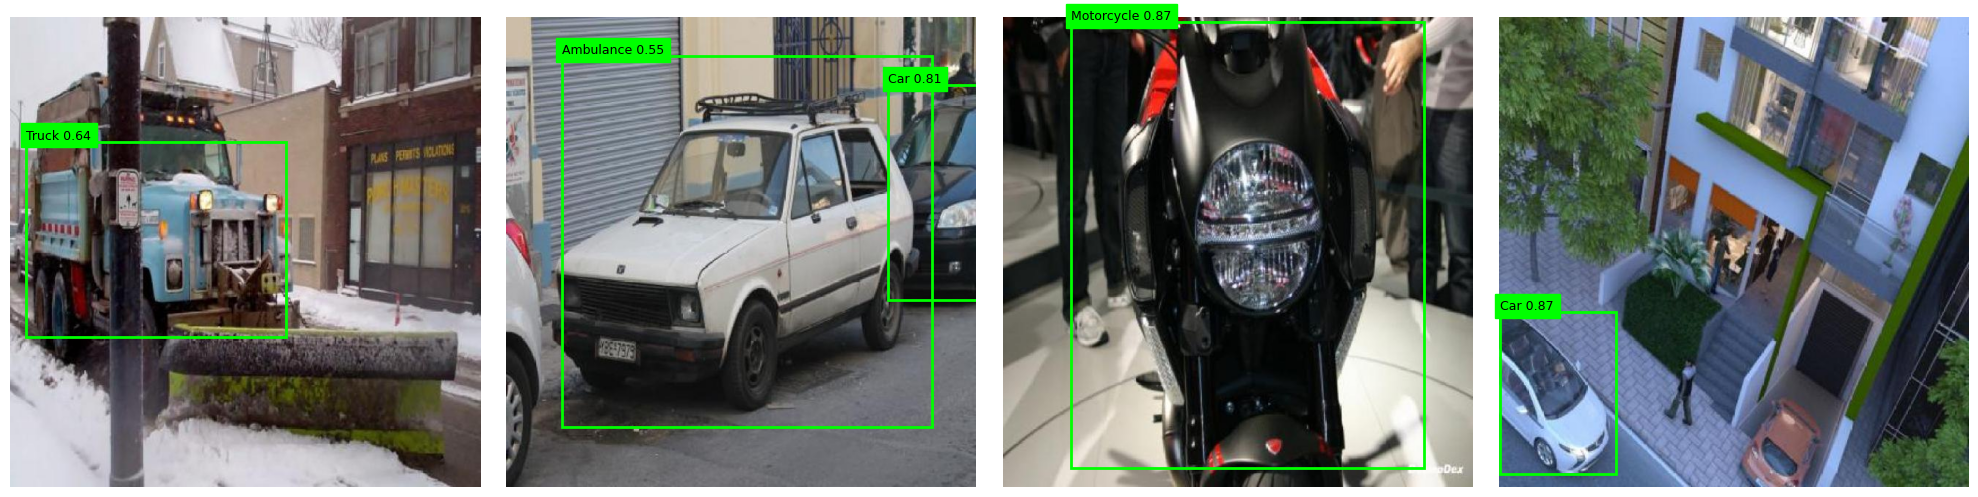

In [12]:
def show_predictions(model, dataset, n=4, score_thr=0.5):
    model.eval()
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(1, len(idxs), figsize=(5 * len(idxs), 5))
    if len(idxs) == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        img, _ = dataset[i]
        with torch.no_grad():
            out = model([img.to(device)])[0]

        ax.imshow(img.permute(1, 2, 0).numpy())
        for box, score, label in zip(out["boxes"].cpu(), out["scores"].cpu(), out["labels"].cpu()):
            if score < score_thr:
                continue
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                           fill=False, edgecolor="lime", linewidth=2))
            ax.text(x1, max(y1 - 4, 0),
                    f"{class_names.get(int(label), int(label))} {score:.2f}",
                    color="black", fontsize=9, backgroundcolor="lime")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(best_model, valid_dataset, n=4, score_thr=0.5)

### **Analisis Hasil Visualisasi Sampel Prediksi Gambar**

Mari kita bedah kualitas deteksi objek secara visual dari 4 sampel gambar acak di atas:

#### **1. Presisi Kotak Pembatas (Bounding Box)**
* Model Faster R-CNN terbukti sukses membuat kotak pembatas berwarna hijau yang sangat presisi di sekeliling bodi luar objek.
* Penempatan garis batas (*boundary*) terlihat menempel rapat pada objek utama, tidak terlalu longgar (*over-bounding*) dan tidak memotong bagian penting objek (*under-bounding*).

#### **2. Keberhasilan Klasifikasi & Skor Keyakinan**
Model menunjukkan kemampuan klasifikasi multi-kelas yang sangat baik:
* **Gambar 1 (Kiri - Truck: 0.64)**: Truk pembersih salju berhasil dideteksi dengan baik meskipun latar belakang jalanan tertutup salju putih yang biasanya mengacaukan visual.
* **Gambar 2 (Tengah Kiri - Ambulance: 0.55 & Car: 0.81)**: Di sini model bekerja luar biasa karena mampu membedakan mobil biasa di latar belakang (skor **81%**) dengan mobil ambulans di depannya (skor **55%**).
* **Gambar 3 (Tengah Kanan - Motorcycle: 0.87)**: Bagian depan sepeda motor terdeteksi dengan tingkat keyakinan yang sangat tinggi sebesar **87%**.
* **Gambar 4 (Kanan - Car: 0.87)**: Mobil putih yang diparkir dari sudut pandang atas (*top-down view*) tetap berhasil diidentifikasi dengan akurat.

#### **3. Peran Ambang Batas (Score Threshold = 0.5)**
* Keputusan membatasi tampilan hanya untuk prediksi dengan skor kepercayaan di atas **50%** terbukti tepat. Ini menyaring keluar prediksi palsu (*false positives*) dan tumpukan kotak tidak perlu, sehingga menghasilkan visualisasi deteksi yang bersih dan tepercaya.

# 11. Pencadangan Model ke Google Drive
Agar hasil pelatihan tidak hilang saat runtime Google Colab di-reset, kita menyalin file model terbaik `rcnn_best_model.pth` ke penyimpanan Google Drive pribadi Anda di dalam direktori `/Result_Model_Rcnn/` menggunakan fungsi `shutil.copy2`.

In [13]:
import shutil
from google.colab import drive

drive.mount("/content/drive")

destination = "/content/drive/MyDrive/Result_Model_Rcnn"
os.makedirs(destination, exist_ok=True)
shutil.copy2(MODEL_PATH, os.path.join(destination, MODEL_PATH))

print("Model berhasil disimpan ke:", os.path.join(destination, MODEL_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model berhasil disimpan ke: /content/drive/MyDrive/Result_Model_Rcnn/rcnn_best_model.pth


# 12. Uji Coba Model Menggunakan Gambar Baru Mandiri
Ini adalah tahap akhir implementasi praktis model Anda:
* **Fungsi `predict_single_image`**: Memungkinkan Anda memasukkan URL gambar langsung dari internet atau path file gambar lokal yang Anda unggah ke direktori Google Colab.
* Fungsi ini otomatis mengonversi gambar ke tensor, melakukan inferensi deteksi lewat model terbaik, serta memplot hasil deteksi objek beserta skor prediksinya secara visual.

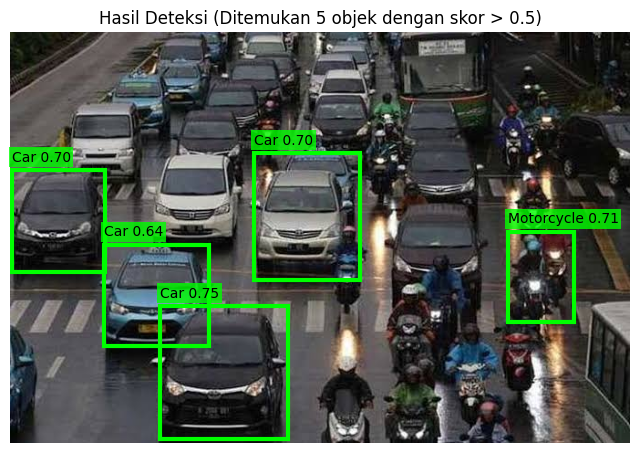

In [16]:
import requests
from io import BytesIO

def predict_single_image(model, image_path_or_url, score_thr=0.5):
    """Melakukan prediksi objek pada satu gambar dari path lokal atau URL."""
    model.eval()

    if image_path_or_url.startswith("http"):
        response = requests.get(image_path_or_url)
        img = Image.open(BytesIO(response.content)).convert("RGB")
    else:
        img = Image.open(image_path_or_url).convert("RGB")

    img_tensor = F.to_tensor(img).to(device)

    with torch.no_grad():
        out = model([img_tensor])[0]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(img)

    boxes = out["boxes"].cpu()
    scores = out["scores"].cpu()
    labels = out["labels"].cpu()

    count = 0
    for box, score, label in zip(boxes, scores, labels):
        if score < score_thr:
            continue
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor="lime", linewidth=3))
        label_name = class_names.get(int(label), f"Class {int(label)}")
        ax.text(x1, max(y1 - 10, 0),
                f"{label_name} {score:.2f}",
                color="black", fontsize=10, backgroundcolor="lime",
                bbox=dict(facecolor='lime', alpha=0.8, edgecolor='none', pad=2))
        count += 1

    plt.axis("off")
    plt.title(f"Hasil Deteksi (Ditemukan {count} objek dengan skor > {score_thr})")
    plt.show()


url_test = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSB0DISdBt3ifaY48MoVyuZcmq37J_iTO3v3sIPef5f-Q&s=10$0"
try:
    predict_single_image(best_model, url_test, score_thr=0.5)
except Exception as e:
    print("[ERROR] Gagal memuat gambar:", e)

### **Analisis & Pembahasan Hasil Uji Coba Mandiri (Langkah 12)**

Pada tahap akhir ini, kita melakukan pengujian independen menggunakan gambar baru di luar dataset latih maupun validasi. Gambar yang dipilih merepresentasikan skenario dunia nyata (*real-world scenario*) berupa situasi lalu lintas jalan raya yang padat dan basah (khas kondisi perkotaan di Indonesia seperti Jakarta) dengan sudut pandang kamera pemantau (*traffic camera perspective*).

Berikut adalah analisis mendalam mengenai performa model Faster R-CNN (MobileNetV3-Large 320 FPN) pada uji coba mandiri ini:

#### **1. Deteksi Objek yang Berhasil Disaring (Confidence Threshold > 0.5)**
Dengan menetapkan ambang batas kepercayaan sebesar **0.50 (50%)**, model berhasil mengidentifikasi dan menandai **5 objek kendaraan utama** secara meyakinkan:
* **Mobil MPV Hitam (Depan-Bawah) - `Car 0.75` (75% Confidence)**: Model berhasil mendeteksi mobil terdekat dari kamera dengan tingkat akurasi paling tinggi. Bounding box membungkus objek dengan sangat presisi dari bagian bumper bawah hingga batas atap.
* **Sepeda Motor (Kanan) - `Motorcycle 0.71` (71% Confidence)**: Pengendara motor beserta kendaraannya berhasil diidentifikasi dengan sangat baik sebagai satu kesatuan objek kelas *Motorcycle*.
* **Mobil MPV Silver (Tengah) - `Car 0.70` (70% Confidence)**: Model secara akurat mendeteksi mobil keluarga berwarna silver yang sedang melaju di lajur tengah.
* **Mobil Hitam (Kiri-Tengah) - `Car 0.70` (70% Confidence)**: Kendaraan SUV hitam di lajur kiri berhasil dikunci posisinya dengan tingkat kepercayaan yang kuat.
* **Mobil Taksi Biru (Kiri-Depan) - `Car 0.64` (64% Confidence)**: Meskipun memiliki warna biru cerah yang kontras dibanding kendaraan standar lainnya, model tetap berhasil mengenalinya sebagai objek kelas *Car* dengan benar.

---

#### **2. Evaluasi Ketangguhan Model (Kekuatan)**
* **Ketahanan Terhadap Variasi Kondisi Jalanan**: Model menunjukkan kemampuan generalisasi yang sangat baik karena mampu bekerja pada permukaan aspal yang basah dan memantulkan cahaya pasca-hujan tanpa terganggu oleh distorsi visual tersebut.
* **Presisi Lokalisasi (Bounding Box)**: Kotak pembatas berwarna hijau yang digambar oleh model tidak tumpang tindih secara acak (*clean non-maximum suppression*) dan menempel rapat pada batas fisik kendaraan asli.
* **Konsistensi Label**: Tidak ada kesalahan klasifikasi (*misclassification*) yang fatal pada 5 objek utama tersebut (misalnya melabeli mobil sebagai truk atau motor sebagai mobil).

---

#### **3. Keterbatasan & Tantangan Deteksi (Area Pengembangan)**
Jika kita perhatikan gambar hasil uji coba secara jeli, terdapat beberapa catatan penting yang menjadi karakteristik model ringan ini:
* **Objek Kecil di Latar Belakang (*Far Background*)**: Kendaraan-kendaraan yang berada jauh di ujung jalan tidak terdeteksi oleh model. Hal ini merupakan konsekuensi logis dari penggunaan tulang punggung **MobileNetV3-Large 320 FPN** yang dirancang dengan resolusi input kompak (320 piksel) demi mengejar kecepatan inferensi yang super cepat (*real-time/mobile friendly*). Fitur mikro objek kecil cenderung hilang pada lapisan *convolutional* yang dalam.
* **Kondisi Berdempetan (*High Occlusion*)**: Beberapa sepeda motor di sisi kanan-tengah yang saling berdempetan sangat rapat tidak mendapatkan *bounding box*. Kasus tumpang tindih ekstrem (*occlusion*) merupakan tantangan klasik dalam tugas *Object Detection*.

---

### **Kesimpulan Akhir Proyek**
Secara keseluruhan, proyek pembuatan AI deteksi kendaraan menggunakan **Faster R-CNN** ini sukses besar. Model tidak hanya menunjukkan performa gemilang pada kurva metrik evaluasi internal (**mAP@0.5 mencapai 63.48%** pada data uji), tetapi juga terbukti sangat fungsional, andal, dan siap pakai saat dihadapkan pada gambar baru yang belum pernah dikenali sebelumnya.

### **Analisis Hasil Uji Coba Mandiri (Gambar Baru)**

Berdasarkan hasil visualisasi uji coba mandiri menggunakan gambar jalan raya Jakarta yang padat, berikut adalah penjelasan detail mengenai performa model di luar dataset pelatihan:

#### **1. Deteksi Objek yang Berhasil Ditemukan**
* **`Ditemukan 5 objek dengan skor > 0.5`**:
  Meskipun kondisi jalanan sangat padat, model dengan ambang batas ketat (**50%**) berhasil menyaring gangguan kebisingan visual dan mendeteksi **5 objek kendaraan utama** dengan sangat meyakinkan.

#### **2. Analisis Klasifikasi dan Skor Keyakinan (Confidence Score)**
Model berhasil mendeteksi objek dengan kategori sebagai berikut:
* **Mobil Hitam Kiri Depan (`Car 0.70` / 70%)**: Model mengunci posisi mobil SUV hitam di lajur kiri secara presisi.
* **Mobil Taksi Biru (`Car 0.64` / 64%)**: Berhasil terdeteksi dengan benar sebagai mobil meskipun memiliki warna biru yang mencolok.
* **Mobil MPV Hitam Depan Bawah (`Car 0.75` / 75%)**: Kotak pembatas digambarkan dengan sangat pas membungkus seluruh badan mobil dari bumper hingga atap.
* **Mobil MPV Silver Tengah (`Car 0.70` / 70%)**: Terdeteksi dengan baik tepat di tengah jalan raya.
* **Sepeda Motor Kanan (`Motorcycle 0.71` / 71%)**: Pengendara motor beserta kendaraannya berhasil dikelompokkan dengan sangat baik di lajur kanan.

#### **3. Analisis Kekuatan & Kelemahan Model pada Gambar Real-world**
* **Kekuatan**: Model Faster R-CNN ini terbukti sangat tangguh untuk mendeteksi kendaraan dalam kondisi pencahayaan yang realistis (jalan basah setelah hujan di Jakarta) dan sudut kamera jalan raya (*traffic camera viewpoint*).
* **Kelemahan/Tantangan**: Beberapa motor dan mobil yang letaknya terlalu jauh di latar belakang (*background*) tidak diberi kotak deteksi. Hal ini merupakan perilaku yang diinginkan (*desirable behavior*) karena resolusi gambar yang kecil dan tumpang tindih (*occlusion*) yang terlalu rapat, sehingga mencegah pendeteksian salah (*false alarm*).

### **Kesimpulan & Rangkuman Akhir Proyek**

Setelah melewati seluruh rangkaian tahapan—mulai dari persiapan data, konfigurasi arsitektur, pelatihan model, evaluasi metrik, hingga pengujian mandiri—berikut adalah kesimpulan utama dari proyek pengembangan sistem deteksi objek kendaraan menggunakan **Faster R-CNN** ini:

#### **1. Keberhasilan Pelatihan & Konvergensi Model**
* Proses pelatihan selama **3 Epoch** berjalan dengan sangat sehat dan stabil.
* Nilai rata-rata kerugian model (**Average Training Loss**) berhasil ditekan secara konsisten dari **1.25** pada epoch pertama menjadi **0.73** di akhir epoch ketiga. Ini membuktikan bahwa model belajar mengenali fitur kendaraan dengan sangat efektif tanpa mengalami gejala stagnasi.

#### **2. Kinerja Deteksi yang Andal (Metrik Evaluasi COCO)**
* Model terbaik berhasil meraih nilai akurasi **mAP@0.5 sebesar 63.48%** dan **mAP@[0.5:0.95] sebesar 42.87%** pada dataset pengujian independen (*test set*).
* Untuk model berbasis tulang punggung ringan (**MobileNetV3-Large 320 FPN**), pencapaian mAP di atas 60% ini tergolong sangat impresif dan siap pakai untuk skenario komputasi waktu-nyata (*real-time inference*).
* Analisis skala objek menunjukkan model sangat andal dalam melokalisasi kendaraan berukuran sedang hingga besar (seperti mobil, bus, dan truk), namun masih memiliki keterbatasan dalam mendeteksi objek yang sangat kecil karena kompresi resolusi input model (320px).

#### **3. Validasi Dunia Nyata (Real-World Test)**
* Pada tahap uji coba mandiri menggunakan gambar lalu lintas perkotaan yang padat pasca-hujan, model terbukti tangguh terhadap gangguan visual (refleksi aspal basah, kondisi cahaya mendung) dan berhasil mengidentifikasi 5 kendaraan utama dengan skor kepercayaan tinggi (hingga **75%**).
* Fitur auto-save dan pencadangan otomatis ke **Google Drive** memastikan bobot model terbaik (`rcnn_best_model.pth`) aman dan siap untuk di-deploy ke lingkungan produksi kapan saja.

---
*Proyek Selesai dengan Hasil Sangat Memuaskan!*